In [1]:
import datetime
import yfinance as yf
import pandas as pd
import numpy as np

In [2]:
start = datetime.datetime(2025,1,1)
end = datetime.datetime(2025,12,31)


In [3]:
thales = yf.download('HO.PA', start=start, end=end)
total = yf.download('TTE.PA', start=start, end=end)
tesla = yf.download('TSLA', start=start, end=end)
lvmh = yf.download('MC.PA', start=start, end=end)

/tmp/ipykernel_1124/345538936.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  thales = yf.download('HO.PA', start=start, end=end)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1124/345538936.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  total = yf.download('TTE.PA', start=start, end=end)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1124/345538936.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  tesla = yf.download('TSLA', start=start, end=end)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1124/345538936.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  lvmh = yf.download('MC.PA', start=start, end=end)
[*********************100%***********************]  1 of 1 completed


In [4]:
stocks = pd.concat([thales['Close'], total['Close'], tesla['Close'], lvmh['Close']], axis = 1)

stocks.columns = ['THALES', 'TOTALEN', 'TESLA', 'LVMH']
stocks


,THALES,TOTALEN,TESLA,LVMH
Date,,,,
2025-01-02,133.640350,48.842030,379.279999,610.562805
2025-01-03,132.766251,49.087467,410.440002,587.404846
2025-01-06,133.786057,49.732876,411.049988,609.794006
2025-01-07,135.534256,49.978313,394.359985,619.307068
2025-01-08,141.264450,50.141937,394.940002,610.851074
...,...,...,...,...
2025-12-23,225.920929,53.140942,485.559998,617.235291
2025-12-24,225.526306,52.912582,485.399994,621.958252
2025-12-26,NaN,NaN,475.190002,NaN


Calcul des returns : r_t = p_t/p_(t-1)

In [5]:
returns = stocks/stocks.shift(1)
returns

,THALES,TOTALEN,TESLA,LVMH
Date,,,,
2025-01-02,NaN,NaN,NaN,NaN
2025-01-03,0.993459,1.005025,1.082156,0.962071
2025-01-06,1.007681,1.013148,1.001486,1.038115
2025-01-07,1.013067,1.004935,0.959397,1.015600
2025-01-08,1.042279,1.003274,1.001471,0.986346
...,...,...,...,...
2025-12-23,0.993492,0.998391,0.993514,0.999363
2025-12-24,0.998253,0.995703,0.999670,1.007652
2025-12-26,NaN,NaN,0.978966,NaN


define log return

In [6]:
logReturns = np.log(returns)
logReturns

,THALES,TOTALEN,TESLA,LVMH
Date,,,,
2025-01-02,NaN,NaN,NaN,NaN
2025-01-03,-0.006562,0.005013,0.078955,-0.038667
2025-01-06,0.007652,0.013062,0.001485,0.037407
2025-01-07,0.012982,0.004923,-0.041451,0.015480
2025-01-08,0.041409,0.003269,0.001470,-0.013748
...,...,...,...,...
2025-12-23,-0.006529,-0.001610,-0.006507,-0.000638
2025-12-24,-0.001748,-0.004306,-0.000330,0.007623
2025-12-26,NaN,NaN,-0.021259,NaN


define sharpe ratio voir si le stock est sur ou sous la capital market line

In [7]:
noOfPortfolios = 10000
weight = np.zeros((noOfPortfolios, 4))
meanLogReturns = logReturns.mean()
Sigma = logReturns.cov()

expectedReturn = np.zeros(noOfPortfolios)
expectedVolatility = np.zeros(noOfPortfolios)
sharpeRatio = np.zeros(noOfPortfolios)

for k in range(noOfPortfolios) :
#generate random weight vector
  w = np.array(np.random.random(4))
  w = w/np.sum(w)
  weight[k,:] = w

#expected log return and vol
  expectedReturn[k] = np.sum(meanLogReturns*w)
  expectedVolatility[k] = np.sqrt(np.dot(w.T, np.dot(Sigma,w)))
#sharpe ratio
  sharpeRatio[k] = expectedReturn[k]/expectedVolatility[k]

In [9]:
maxIndex = sharpeRatio.argmax()
weight[maxIndex,:]


array([0.68427119, 0.14188322, 0.10268597, 0.07115962])

<function matplotlib.pyplot.show(close=None, block=None)>

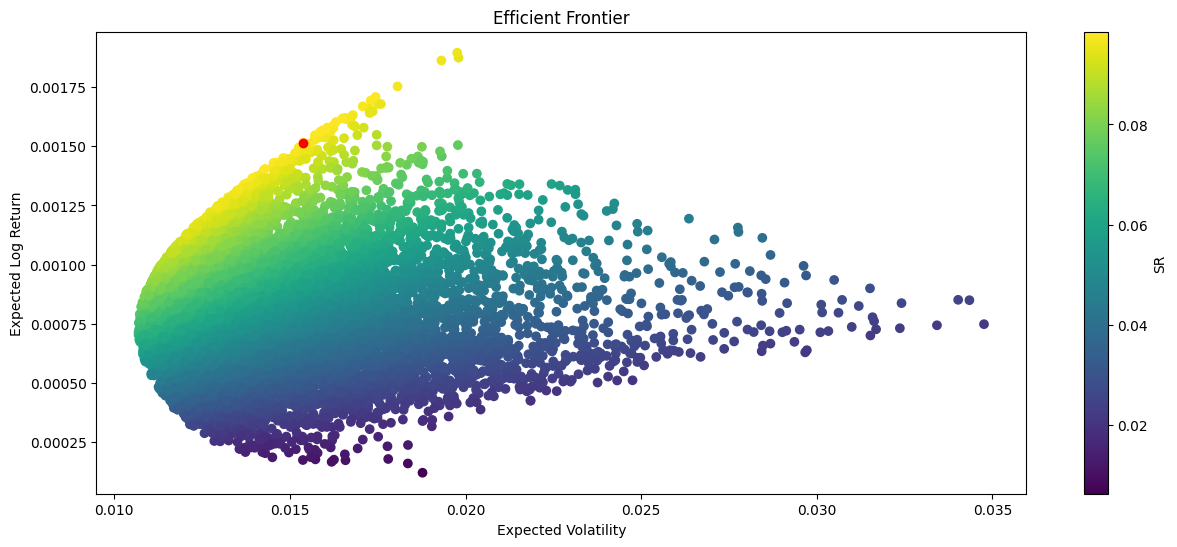

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,6))
plt.scatter(expectedVolatility, expectedReturn, c=sharpeRatio)
plt.xlabel('Expected Volatility')
plt.ylabel('Expected Log Return')
plt.title('Efficient Frontier')
plt.colorbar(label ='SR')
plt.scatter(expectedVolatility[maxIndex], expectedReturn[maxIndex], c='Red')
plt.show

Efficient Markowitz Frontier

In [11]:
from scipy.optimize import minimize

def negativeSR(w):
  w = np.array(w)
  R = np.sum(meanLogReturns*w)
  V = np.sqrt(np.dot(w.T, np.dot(Sigma,w)))
  SR = R/V
  return -1*SR

def checkSumtoONE(w) :
  return np.sum(w)-1

w0 = [ 0.25,0.25,0.25,0.25 ]
bounds = [(0,1),(0,1),(0,1),(0,1)]
constraints = ({'type':'eq', 'fun': checkSumtoONE})

w_opt = minimize(negativeSR,w0,method='SLSQP', bounds=bounds, constraints = constraints)
w_opt

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: -0.09865839171438184
           x: [ 6.790e-01  1.908e-01  1.044e-01  2.585e-02]
         nit: 12
         jac: [-4.936e-05 -5.919e-05  5.097e-04 -3.245e-04]
        nfev: 60
        njev: 12
 multipliers: [-1.136e-06]

In [12]:
w_opt.x

array([0.67896175, 0.19081491, 0.10437054, 0.0258528 ])

In [13]:
returns = np.linspace(0, 0.002, 100)
volatility_opt = []
def minimzeMyVol (w) :
  w = np.array(w)
  V = np.sqrt(np.dot(w.T, np.dot(Sigma,w)))
  return V

def getReturn(w) :
  w = np.array(w)
  R = np.sum(meanLogReturns*w)
  return R

for R in returns :
  constraints = ({'type':'eq', 'fun': checkSumtoONE},
                 {'type':'eq', 'fun': lambda w: getReturn(w) - R})
  opt = minimize(minimzeMyVol, w0, bounds=bounds, constraints=constraints)
  volatility_opt.append(opt.fun)